# Assignment 02 - Transforms

This assignment covers robustness testing using data transforms with PyTorch and TorchVision.

## Introduction

As we have seen in class, PyTorch and its related packages provide a powerful means of transforming data in a way that is decoupled from the actual code in our training loop.

The `torch.utils.data.Dataset` and `torch.utils.data.DataLoader` classes provide interfaces for accessing datasets and loading data into our training pipelines. When combined with `torchvision.transforms`, these tools allow us to transform our data without making changes to our core training code. This is incredibly useful for data augmentation, domain generalization, and robustness testing.

For *data augmentation*, transforms can be applied before training to produce useful variation in the dataset, and instill expert knowledge into our models by having experts select which transforms we apply to the training data (e.g., applying rotations to a model which must be rotation invariant), potentially improving model generalization.

Data augmentation is one means to achieve *domain generalization*, i.e., training a model to perform well on domains not encountered during training. Transforms can be applied during training to help us improve our model's ability to generalize to new domains. For example, varying the color of the background randomly ensures the model is not incorrectly sensitive to background color and will not break in a domain with different background colors.

For robustness testing, transforms can be applied after training to assess our model's robustness to controlled perturbations applied to the evaluation data, e.g., blur, color changes, perspective changes, and other variations. We can apply transforms to various degrees using the parameters that PyTorch exposes to adjust the transform. This enables us to extract performance curves for our models which go beyond simply displaying a confusion matrix as the output of model training and show the practical limitations that the model will have when encountering variation from the training data.

This assignment will focus on applying transforms for robustness testing.

## Development and Computing Environment

For this assignment, you may use whichever computing environment you like, whether that be your local computer, Amarel, or another environment. In subsequent assignments, Amarel will be required due to the compute workloads we will need so it is recommended (though not yet required) to begin familiarizing yourself with it and employing it for assignments.

## Directions

In this assignment, we will train a model and assess its robustness using PyTorch. To do this, we will carry out the following steps.

1. **Load Data**: This step will require us to import a torch Dataset and use a torch DataLoader to access it. You may use any dataset you like, as long as it supports image classification (since this assignment is focused on image transforms and assessing accuracy of classification tasks). Datasets built into PyTorch may be used. **0.25 points extra credit will be awarded for implementing a custom Dataset.** Be sure to pick a dataset you have the capacity to train a model on in your development environment. To keep the assignment fair, grading will not be based on the size of the dataset used in any way. Plot a few of the images to ensure you have loaded the data correctly. As always, be sure to divide your dataset into separate training and test sets.

2. **Define the Training Pipeline**: This step will require us to define the class which specifies our neural network architecture, and to define the functions which allow us to train it. We have seen examples of this before, both in class and prior assignments. Be sure to choose an architecture with sufficient capacity to learn the dataset you have chosen in step #1.

3. **Train the Model**: In this step we will use our training functions from step #2 to train a model. Once the model is trained, report baseline test accuracy on untransformed images.

4. **Use Transforms to Test the Model's Robustness Against Blur**: In this step, we will test the model for robustness against an image blur transform. This step will require us to run model inference on the **test** set repeatedly, increasing the amount of image blur with each run. For each image blur level, we will need to save the accuracy, then plot the accuracy against the degree of blur (choose an appropriate metric for the degree of blur), including the baseline accuracy with no blur in the plot. The end result of this step should be a plot of accuracy with respect to degree of blur. Test over a meaningful range of blur severity, aiming to characterize the model's limitations. If performance does not fall to random chance within that range, explain this in your results.

5. **Robustness Test the Model Against a Transform of Your Choice**: In this step, we will test the model for robustness against a transform of our choice (perhaps perspective changes, color changes, or contrast changes). Like Step 4, this step will require us to run inference on the test set with increasing degrees of transformation and plot the resulting accuracy.

## Grading

This assignment is entirely open ended and will not be auto-graded. Each step is worth 20% of the assignment grade. For each step, ensure the following conditions are met to get full credit.

| **Step** | **Criteria for Full Credit** |
|----|----|
| 1. Data Loading | An appropriate image classification dataset is loaded using Dataset and DataLoader, separate training and test sets are established, and example images are visualized. |
| 2. Training Pipeline Definition | A suitable neural network architecture and functional training pipeline are implemented without code errors. |
| 3. Training | The model trains for a sufficient number of epochs, training loss decreases, and baseline test accuracy is reported. |
| 4. Robustness Test - Blur  | A curve of accuracy with respect to degree of blur is produced over a meaningful range of blur severity and is of professional quality. |
| 5. Robustness Test - Other  | A curve of accuracy with respect to degree of transformation over a meaningful range of transformation severity is produced and is of professional quality. |

## Tips

This assignment is intentionally open ended. **No starter code is provided.** The goal of this assignment is to test your ability to put the concepts we have discussed in class into practice.

The steps should be similar, but not necessarily exactly the same, as steps we have discussed in class.

**Assignment 02 - Transforms: Robustness Testing on Cervical Cytology (Herlev Pap smear)**
 Cervical cancer is the classic HPV-induced cancer; koilocytes are the cell
changes characteristic of HPV infection. For this I classify Pap smear cell types and test how
 robust the trained model is to Gaussian blur and to contrast changes.

## Imports

In [13]:
import math
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from PIL import Image
from torch.utils.data import DataLoader, Dataset

## Step 1 - Load Data

Use the cell below (or make additional cells) to load a torch Dataset and use a torch DataLoader to access it. You may use any dataset you like, as long as it supports image classification (since this assignment is focused on image transforms). Datasets built into PyTorch may be used.

**0.25 points extra credit will be awarded for implementing a custom Dataset.** Be sure to pick a dataset you have the capacity to train a model on in your development environment. To keep the assignment fair, grading will not be based on the size of the dataset used in any way. Plot a few of the images to ensure you have loaded the data correctly.


In [ ]:
# ---------------- CONFIG ----------------
DATA_ROOT = Path.home() / "Downloads" / "Herlev Dataset"   # folder containing train/ and test/
IMG_SIZE = 128         
BATCH_SIZE = 64
EPOCHS = 15            
LR = 3e-4              
SEED = 0
TEST_FRACTION = 0.2
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
# ----------------------------------------

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")      # Apple Silicon GPU
else:
    device = torch.device("cpu")
print("Using device:", device)


NORM = T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))


print("Dataset folder found:", DATA_ROOT.is_dir())

Using device: cpu
Dataset folder found: True


Classes: ['carcinoma_in_situ', 'dysplastic', 'normal']
Train: 636 images | Test: 281 images
  carcinoma_in_situ      train  104   test   46
  dysplastic             train  363   test  162
  normal                 train  169   test   73
Random guessing: 33.3% | Always guessing the largest class: 57.7%


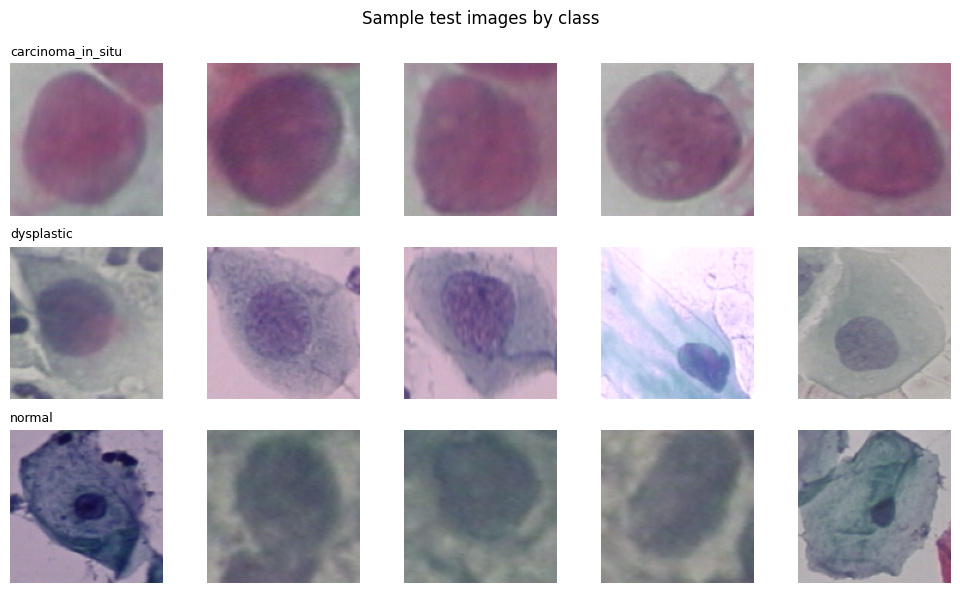

In [ ]:
IMG_EXTS = {".bmp", ".png", ".jpg", ".jpeg"}

def group_label(name):
    """Group the 7 Herlev classes into 3 groups."""
    if name.startswith("normal"):
        return "normal"
    if name.endswith("dysplastic"):
        return "dysplastic"
    return "carcinoma_in_situ"

def load_records(split_dir):
    """Return a list of (image_path, class_name) from folders like split_dir/<class>/*.bmp"""
    records = []
    for class_dir in sorted(Path(split_dir).iterdir()):
        if not class_dir.is_dir():
            continue
        for p in sorted(class_dir.iterdir()):
            if (p.suffix.lower() in IMG_EXTS and not p.name.startswith("._")
                    and not p.stem.lower().endswith("-d")):   
                records.append((p, class_dir.name))
    return records


class HerlevDataset(Dataset):
    """Custom Dataset: loads and resizes each image once, applies `transform` on access."""

    def __init__(self, records, class_to_idx, img_size=IMG_SIZE, transform=None):
        self.transform = transform
        self.labels = [class_to_idx[cls] for _, cls in records]
        self.images = [Image.open(p).convert("RGB").resize((img_size, img_size), Image.BILINEAR)
                       for p, _ in records]

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        img = self.images[i]
        if self.transform is not None:
            img = self.transform(img)
        return img, self.labels[i]


train_recs = load_records(DATA_ROOT / "train")
test_recs = load_records(DATA_ROOT / "test")

def group_label(name):
    """Group the 7 Herlev classes into 3 groups."""
    if name.startswith("normal"):
        return "normal"
    if name.endswith("dysplastic"):
        return "dysplastic"
    return "carcinoma_in_situ"

train_recs = [(p, group_label(c)) for p, c in train_recs]
test_recs = [(p, group_label(c)) for p, c in test_recs]


all_recs = train_recs + test_recs
groups = {}
for p, c in all_recs:
    groups.setdefault((c, p.stem.rsplit("-", 1)[0]), []).append((p, c))

rng = random.Random(SEED)
train_recs, test_recs = [], []
for c in sorted({c for _, c in all_recs}):
    keys = sorted(k for k in groups if k[0] == c)
    rng.shuffle(keys)
    n_test = max(1, round(0.3 * len(keys)))
    for i, k in enumerate(keys):
        (test_recs if i < n_test else train_recs).extend(groups[k])

classes = sorted({cls for _, cls in train_recs})
class_to_idx = {c: i for i, c in enumerate(classes)}

print("Classes:", classes)
print(f"Train: {len(train_recs)} images | Test: {len(test_recs)} images")
for c in classes:
    print(f"  {c:22s} train {sum(cls == c for _, cls in train_recs):4d}   "
          f"test {sum(cls == c for _, cls in test_recs):4d}")

train_tf = T.Compose([T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
                      T.RandomRotation(90), T.ToTensor(), NORM])
base_tf = T.Compose([T.ToTensor(), NORM])

train_ds = HerlevDataset(train_recs, class_to_idx, transform=train_tf)
test_ds = HerlevDataset(test_recs, class_to_idx, transform=base_tf)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

from collections import Counter
CHANCE = 1 / len(classes)
MAJORITY = max(Counter(test_ds.labels).values()) / len(test_ds)
print(f"Random guessing: {CHANCE:.1%} | Always guessing the largest class: {MAJORITY:.1%}")



fig, axes = plt.subplots(len(classes), 5, figsize=(10, 2 * len(classes)))
for r, c in enumerate(classes):
    idxs = [i for i, l in enumerate(test_ds.labels) if l == class_to_idx[c]][:5]
    for k in range(5):
        ax = axes[r, k]
        ax.axis("off")
        if k < len(idxs):
            ax.imshow(test_ds.images[idxs[k]])
        if k == 0:
            ax.set_title(c, fontsize=9, loc="left")
fig.suptitle("Sample test images by class")
fig.tight_layout()
fig.savefig(FIG_DIR / "sample_images.png", dpi=200, bbox_inches="tight")
plt.show()

## Step 2 - Define Training Pipeline

Define a training pipeline like those we have seen in class. Define the class that specifies our neural network architecture and the functions which allow us to train it. We have seen examples of this before, both in class and prior assignments.

Be sure to choose an architecture with sufficient capacity to learn the dataset you have chosen in step #1.

Tip: if you see your architecture is insufficient to learn the dataset you have chosen when you run step 3, you may need to return to step #2 to make your architecture wider or deeper.

In [16]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()

        def block(in_ch, out_ch):
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(),
                nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(),
                nn.MaxPool2d(2),
            )

        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3),
            nn.Linear(128, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
        n += x.size(0)
    return total_loss / n


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct, n = 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        correct += (model(x).argmax(1) == y).sum().item()
        n += x.size(0)
    return correct / n

In [10]:
from torchvision import models

class CellClassifier(nn.Module):
    """ResNet18 pretrained on ImageNet, with a new final layer for our cell classes."""
    def __init__(self, n_classes):
        super().__init__()
        self.net = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        self.net.fc = nn.Linear(self.net.fc.in_features, n_classes)

    def forward(self, x):
        return self.net(x)

## Step 3 - Train a Model

Kick off your training run here. Be sure to print or plot the error with respect to the number of epochs so you can see if your model is learning. Once training is complete, report the model's baseline accuracy on the untransformed test set.


Epoch  1/15  train loss 0.7873  test acc 0.730
Epoch  2/15  train loss 0.4803  test acc 0.776
Epoch  3/15  train loss 0.4587  test acc 0.776
Epoch  4/15  train loss 0.3875  test acc 0.744
Epoch  5/15  train loss 0.3271  test acc 0.833
Epoch  6/15  train loss 0.2928  test acc 0.790
Epoch  7/15  train loss 0.2059  test acc 0.808
Epoch  8/15  train loss 0.2044  test acc 0.790
Epoch  9/15  train loss 0.2226  test acc 0.808
Epoch 10/15  train loss 0.2614  test acc 0.786
Epoch 11/15  train loss 0.1743  test acc 0.826
Epoch 12/15  train loss 0.2120  test acc 0.794
Epoch 13/15  train loss 0.1771  test acc 0.822
Epoch 14/15  train loss 0.1666  test acc 0.794
Epoch 15/15  train loss 0.1503  test acc 0.851

Baseline test accuracy (no transform): 0.851


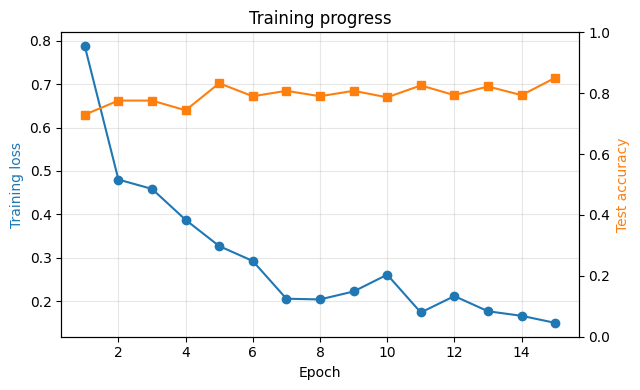

In [17]:
model = CellClassifier(len(classes)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
criterion = nn.CrossEntropyLoss()

train_losses, test_accs = [], []
for epoch in range(1, EPOCHS + 1):
    loss = train_one_epoch(model, train_loader, optimizer, criterion)
    acc = evaluate(model, test_loader)
    train_losses.append(loss)
    test_accs.append(acc)
    print(f"Epoch {epoch:2d}/{EPOCHS}  train loss {loss:.4f}  test acc {acc:.3f}")

baseline_acc = evaluate(model, test_loader)
print(f"\nBaseline test accuracy (no transform): {baseline_acc:.3f}")

# Plot training loss (and test accuracy) vs. epoch
fig, ax1 = plt.subplots(figsize=(6.5, 4))
ax1.plot(range(1, EPOCHS + 1), train_losses, "o-", color="tab:blue")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Training loss", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(range(1, EPOCHS + 1), test_accs, "s-", color="tab:orange")
ax2.set_ylabel("Test accuracy", color="tab:orange")
ax2.set_ylim(0, 1)
ax1.set_title("Training progress")
ax1.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "training_curve.png", dpi=200)
plt.show()

## Step 4 - Use Transforms to Robustness Test the Model Against Image Blur

Use the cell below (or add more cells) to write code which repeatedly (e.g., in a for-loop) infers your model on your test set. Each time you do so, apply a blur transform with an increasing amount of blur. Compute and save the average accuracy across the entire test set and then plot the accuracy against the degree of blur (choose an appropriate metric for the degree of blur). Be sure to include the baseline accuracy with no blur applied in the plot. The end result of this step should be a plot of accuracy with respect to degree of blur. Test over a meaningful range of blur severity to characterize the model's limitations. If the model does not fail within that range, explain this in your results.

Include a brief discussion of what your results indicate about the robustness and limitations of your model.


In [18]:
def accuracy_under_transform(pil_ops):
    """Apply PIL-level transforms to the TEST images, then evaluate."""
    test_ds.transform = T.Compose(pil_ops + [T.ToTensor(), NORM])
    acc = evaluate(model, DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False))
    test_ds.transform = base_tf
    return acc


def plot_sweep(xs, accs, xlabel, title, fname, baseline_x):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(xs, accs, "o-", lw=2, ms=6, color="tab:blue", label="Test accuracy")
    ax.axhline(CHANCE, ls="--", color="gray", label=f"Random guessing ({CHANCE:.0%})")
    ax.axhline(MAJORITY, ls=":", color="tab:green", label=f"Always guess largest class ({MAJORITY:.0%})")
    bi = xs.index(baseline_x)
    ax.plot(xs[bi], accs[bi], "o", ms=12, mfc="none", mec="tab:red", mew=2,
            label=f"Baseline, no transform ({accs[bi]:.1%})")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Test accuracy")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(loc="best")
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname, dpi=200)
    plt.show()

sigma    0: accuracy 0.851
sigma  0.5: accuracy 0.847
sigma    1: accuracy 0.794
sigma  1.5: accuracy 0.687
sigma    2: accuracy 0.548
sigma    3: accuracy 0.349
sigma    4: accuracy 0.299
sigma    6: accuracy 0.285
sigma    8: accuracy 0.331
sigma   10: accuracy 0.374
sigma   12: accuracy 0.409
sigma   16: accuracy 0.473


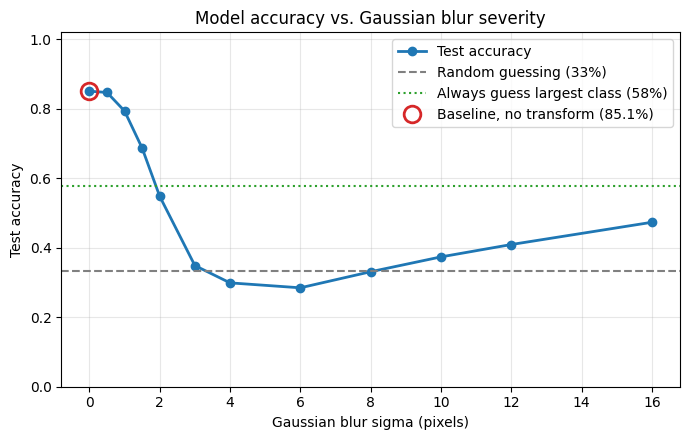

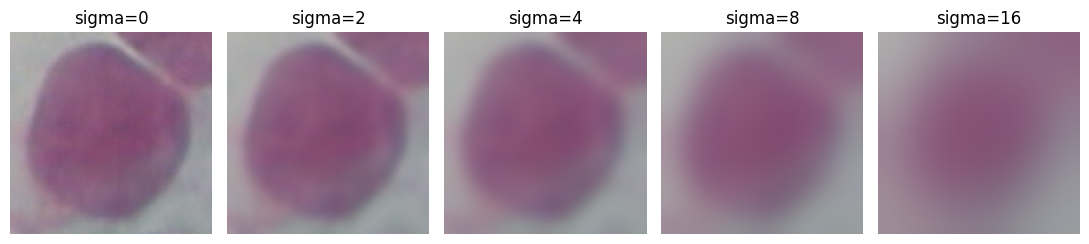

In [ ]:
KMAX = IMG_SIZE - 1 if (IMG_SIZE - 1) % 2 == 1 else IMG_SIZE - 2


def blur_ops(sigma):
    if sigma == 0:
        return []                      
    k = min(int(2 * math.ceil(3 * sigma) + 1), KMAX)
    return [T.GaussianBlur(kernel_size=k, sigma=sigma)]


sigmas = [0, 0.5, 1, 1.5, 2, 3, 4, 6, 8, 10, 12, 16]
blur_accs = []
for s in sigmas:
    a = accuracy_under_transform(blur_ops(s))
    blur_accs.append(a)
    print(f"sigma {s:>4}: accuracy {a:.3f}")

plot_sweep(sigmas, blur_accs, "Gaussian blur sigma (pixels)",
           "Model accuracy vs. Gaussian blur severity", "robustness_blur.png", baseline_x=0)

# Show what the blur looks like
demo = test_ds.images[0]
fig, axes = plt.subplots(1, 5, figsize=(11, 2.8))
for ax, s in zip(axes, [0, 2, 4, 8, 16]):
    ax.imshow(T.Compose(blur_ops(s))(demo) if s else demo)
    ax.set_title(f"sigma={s}")
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "blur_examples.png", dpi=200)
plt.show()

In [20]:
def predictions_under_transform(pil_ops):
    test_ds.transform = T.Compose(pil_ops + [T.ToTensor(), NORM])
    model.eval()
    preds = []
    with torch.no_grad():
        for x, _ in DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False):
            preds += model(x.to(device)).argmax(1).cpu().tolist()
    test_ds.transform = base_tf
    return Counter(classes[k] for k in preds)

for s in [0, 3, 6, 16]:
    print(f"sigma {s:>2}:", dict(predictions_under_transform(blur_ops(s))))
print("true:    ", {classes[k]: v for k, v in sorted(Counter(test_ds.labels).items())})

sigma  0: {'carcinoma_in_situ': 33, 'dysplastic': 178, 'normal': 70}
sigma  3: {'carcinoma_in_situ': 171, 'dysplastic': 22, 'normal': 88}
sigma  6: {'carcinoma_in_situ': 180, 'dysplastic': 45, 'normal': 56}
sigma 16: {'dysplastic': 182, 'carcinoma_in_situ': 52, 'normal': 47}
true:     {'carcinoma_in_situ': 46, 'dysplastic': 162, 'normal': 73}


### Step 4 Discussion: Blur

The model gets 85.1% on the unblurred test set. It handles very slight blur fine (84.7% at sigma = 0.5), but it drops fast after that: 79.4% at sigma = 1 and 54.8% at sigma = 2, which is already worse than always guessing the biggest class (57.7%). By sigma = 3 it's at 34.9%, about the same as random guessing for three classes (33.3%), and the lowest point is 28.5% at sigma = 6. So the model does fail within the range I tested.

My guess is the model depends on fine detail like nucleus texture and sharp edges, and blur wipes that out. That's a real limitation, since microscope images are often a little out of focus. The test set is only 281 images, so differences of a few points aren't very meaningful.

Accuracy goes back up at heavy blur (47.3% at sigma = 16), which looked odd, so I counted what the model was predicting. At sigma = 3 and 6 it called most images carcinoma in situ (171 and 180 of 281), even though that class is only 16% of the test set. At sigma = 16 it called most images dysplastic (182 of 281), which is the biggest class at 58%. So the rise comes from the model defaulting to the common class, not from it getting better at telling cells apart. I didn't look into why specifically the default class changes with the blur level.

## Step 5 - Robustness Test the Model Against a Transform of Your Choice

Repeat Step 4 for a transform of your choice. Create a plot showing how model accuracy changes as the transformation is applied more drastically. Briefly explain why you selected this transform, how you parameterized its severity, and what the results tell you about your model's robustness. Compare the results with your blur experiment. When selecting transformations, and when determining the degree to which they should be applied, consider whether the original image labels remain valid after the transformation is applied. For example, a 6 rotated far enough may become visually indistinguishable from a 9!

As in Step 4, include the untransformed baseline and use the same test samples across all transformation levels.

contrast factor  0.1: accuracy 0.520
contrast factor  0.2: accuracy 0.555
contrast factor  0.3: accuracy 0.616
contrast factor  0.4: accuracy 0.680
contrast factor  0.6: accuracy 0.687
contrast factor  0.8: accuracy 0.794
contrast factor  1.0: accuracy 0.851
contrast factor 1.25: accuracy 0.790
contrast factor  1.5: accuracy 0.737
contrast factor  2.0: accuracy 0.698
contrast factor  2.5: accuracy 0.690
contrast factor  3.0: accuracy 0.680


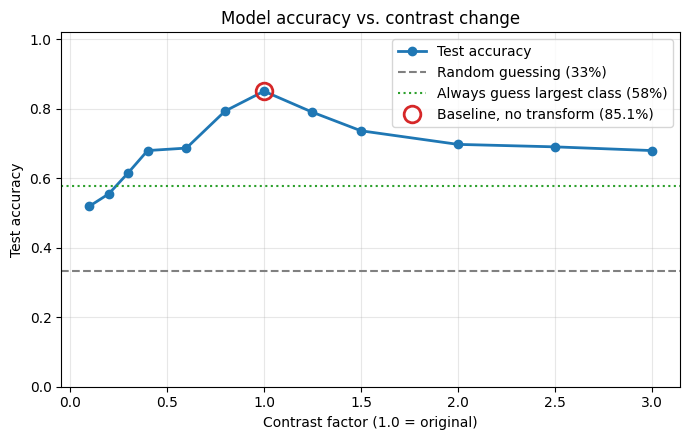

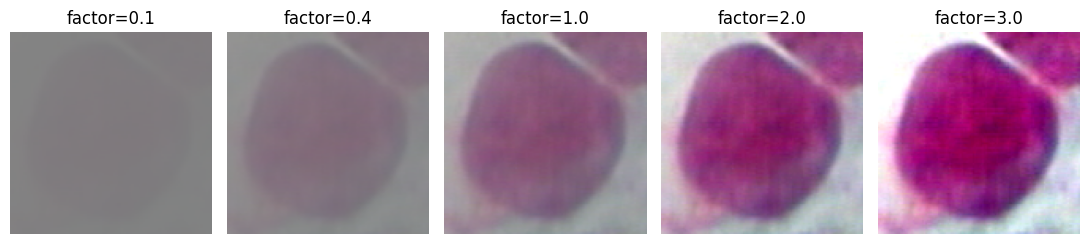

factor 0.1: {'dysplastic': 231, 'carcinoma_in_situ': 32, 'normal': 18}
factor 0.4: {'dysplastic': 211, 'carcinoma_in_situ': 18, 'normal': 52}
factor 1.0: {'carcinoma_in_situ': 33, 'dysplastic': 178, 'normal': 70}
factor 3.0: {'dysplastic': 250, 'normal': 31}


In [ ]:
# Contrast factor: 1.0 = original, <1 = washed out, >1 = more contrast.
# I stop at 0.1 on the low end: at 0.0 every image is a flat gray square,
# so the cell is gone and the label can't be recovered by anyone.
factors = [0.1, 0.2, 0.3, 0.4, 0.6, 0.8, 1.0, 1.25, 1.5, 2.0, 2.5, 3.0]
contrast_accs = []
for f in factors:
    a = accuracy_under_transform([T.Lambda(lambda im, f=f: TF.adjust_contrast(im, f))])
    contrast_accs.append(a)
    print(f"contrast factor {f:>4}: accuracy {a:.3f}")

plot_sweep(factors, contrast_accs, "Contrast factor (1.0 = original)",
           "Model accuracy vs. contrast change", "robustness_contrast.png", baseline_x=1.0)

# Show what the transform looks like
demo = test_ds.images[0]
fig, axes = plt.subplots(1, 5, figsize=(11, 2.8))
for ax, f in zip(axes, [0.1, 0.4, 1.0, 2.0, 3.0]):
    ax.imshow(TF.adjust_contrast(demo, f))
    ax.set_title(f"factor={f}")
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "contrast_examples.png", dpi=200)
plt.show()


for f in [0.1, 0.4, 1.0, 3.0]:
    print(f"factor {f:>3}:", dict(predictions_under_transform(
        [T.Lambda(lambda im, f=f: TF.adjust_contrast(im, f))])))